# Einstein-radius checks: line-of-sight effects and power-law slope

This notebook builds a small galaxy-galaxy lens population with `slsim` (following
`slsim-tutorials/notebooks/MainNotebooks/galaxy_galaxy_lensing_tutorial.ipynb`), selects a handful of
lenses, and for each of them checks:

1. **LOS effects** – how much the Einstein radius changes when the line-of-sight convergence
   $\kappa_{\rm ext}$ and shear $\gamma_{\rm ext}$ are included vs. switched off.
2. **Power-law slope** – how much the Einstein radius changes when a mass-density slope
   $\gamma_{\rm pl}$ is assigned to the deflector vs. the default isothermal ($\gamma_{\rm pl}=2$) case.

Two Einstein-radius estimates are compared throughout:

- `Lens.einstein_radius` – slsim's analytic estimate. For an EPL deflector this is
  $\theta_E = \theta_{E,\rm SIS}(\sigma_v)\,/\,(1-\kappa_{\rm ext})^{1/(\gamma_{\rm pl}-1)}$; external shear does not enter.
- **numerical** – `lenstronomy`'s `effective_einstein_radius` evaluated on the full lens model
  (EPL + SHEAR + CONVERGENCE), which includes both ellipticity and shear.

In [1]:
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from astropy.units import Quantity
from lenstronomy.Analysis.lens_profile import LensProfileAnalysis

import slsim.Pipelines as pipelines
from slsim.Deflectors.DeflectorPopulation.galaxy_deflectors import GalaxyDeflectors
from slsim.Deflectors.mass import Mass
from slsim.Lenses.lens import Lens
from slsim.Lenses.LensPopulation.lens_pop import LensPop
from slsim.LOS.los_individual import LOSIndividual
from slsim.LOS.los_pop import LOSPop
from slsim.Sources.SourcePopulation.galaxies import Galaxies

pd.set_option("display.precision", 4)

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


## 1. Build a galaxy-galaxy lens population

Same set-up as the tutorial, with a smaller sky area since we only need a few lenses.
Line-of-sight distortions are drawn from slsim's default $\kappa_{\rm ext}$–$\gamma_{\rm ext}$ distribution (`LOSPop(los_bool=True)`).

In [2]:
np.random.seed(42)

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
sky_area = Quantity(1, "deg2")  # area for which lenses are rendered
sky_area_galaxies = Quantity(0.1, "deg2")  # area from which deflectors/sources are drawn

kwargs_deflector_cut = {"band": "g", "band_max": 26, "z_min": 0.01, "z_max": 2.5}
kwargs_source_cut = {"band": "g", "band_max": 26, "z_min": 0.1, "z_max": 5.0}

In [3]:
galaxy_simulation_pipeline = pipelines.SkyPyPipeline(
    skypy_config=None, sky_area=sky_area_galaxies, filters=None, cosmo=cosmo
)

lens_galaxies = GalaxyDeflectors(
    red_galaxy_list=galaxy_simulation_pipeline.red_galaxies,
    blue_galaxy_list=galaxy_simulation_pipeline.blue_galaxies,
    kwargs_cut=kwargs_deflector_cut,
    kwargs_mass2light=None,
    catalog_type="skypy",
    cosmo=cosmo,
    sky_area=sky_area_galaxies,
)

source_galaxies = Galaxies(
    galaxy_list=galaxy_simulation_pipeline.blue_galaxies,
    kwargs_cut=kwargs_source_cut,
    cosmo=cosmo,
    sky_area=sky_area_galaxies,
    catalog_type="skypy",
    extended_source_type="single_sersic",
)

gg_lens_pop = LensPop(
    deflector_population=lens_galaxies,
    source_population=source_galaxies,
    cosmo=cosmo,
    sky_area=sky_area,
    los_pop=LOSPop(los_bool=True),
)

## 2. Select lenses and define helpers

`rebuild_lens` returns a copy of a lens with a different line of sight and/or different EPL mass
parameters (e.g. `gamma_pl`, `sis_convention`), keeping the same deflector light, velocity dispersion,
ellipticity and source.

In [4]:
n_lenses = 8
kwargs_lens_cut = {"min_image_separation": 0.8, "max_image_separation": 10}

lenses = [gg_lens_pop.select_lens_at_random(**kwargs_lens_cut) for _ in range(n_lenses)]
lenses.sort(key=lambda lens: lens.einstein_radius[0])

/home/paras/sharmapyenv/lib64/python3.12/site-packages/lenstronomy/LensModel/Util/epl_util.py:21: RuntimeWarning: invalid value encountered in scalar divide
  return (x3**2 * (y1 - y2) + x1**2 * (y2 - y3) + x2**2 * (-y1 + y3)) / div


In [5]:
NO_LOS = LOSIndividual(kappa=0, gamma=[0, 0])


def rebuild_lens(lens, los_class=None, **kwargs_mass_update):
    """Copy of `lens` with a new line of sight and/or updated EPL mass parameters."""
    deflector = copy.deepcopy(lens.deflector)
    if kwargs_mass_update:
        e1, e2 = deflector.mass.mass_ellipticity
        kwargs_mass = {
            "mass_type": "EPL",
            "vel_disp": deflector.velocity_dispersion(cosmo=cosmo),
            "gamma_pl": deflector.mass_properties["gamma_pl"],
            "e1": e1,
            "e2": e2,
        }
        kwargs_mass.update(kwargs_mass_update)
        deflector.mass = Mass(light=deflector.light, **kwargs_mass)
    return Lens(
        source_class=lens.source(0),
        deflector_class=deflector,
        cosmo=cosmo,
        los_class=lens.los_class if los_class is None else los_class,
    )


def numerical_einstein_radius(lens):
    """Effective Einstein radius of the full lenstronomy lens model (incl. shear and convergence)."""
    lens_model, kwargs_lens = lens.deflector_mass_model_lenstronomy(source_index=0)
    return LensProfileAnalysis(lens_model).effective_einstein_radius(
        kwargs_lens, r_min=1e-3, r_max=5e1, num_points=100
    )


def lens_summary(lens):
    kappa, gamma1, gamma2 = lens.los_linear_distortions
    return {
        "z_l": lens.deflector_redshift,
        "z_s": lens.source_redshift_list[0],
        "sigma_v [km/s]": lens.deflector_velocity_dispersion(),
        "kappa_ext": kappa,
        "gamma_ext": np.hypot(gamma1, gamma2),
    }


pd.DataFrame([lens_summary(lens) for lens in lenses])

,z_l,z_s,sigma_v [km/s],kappa_ext,gamma_ext
0,0.5723,2.6586,146.7049,0.0046,0.0389
1,0.4710,2.8878,141.6127,-0.0097,0.0200
2,0.6101,2.0126,158.1689,-0.0037,0.0261
3,0.5117,0.9505,194.9755,0.0185,0.0144
4,0.7050,2.2689,171.2812,-0.0280,0.0306
5,0.3141,1.3846,165.5048,-0.0177,0.0043
6,0.9172,2.0909,219.0140,-0.0318,0.0249
7,0.2774,2.3457,183.7316,-0.0195,0.0410


## 3. Check 1: Einstein radius with and without LOS effects

For each lens we compare the Einstein radius with its drawn line of sight ($\kappa_{\rm ext}$, $\gamma_{\rm ext}$)
against the same lens with $\kappa_{\rm ext}=\gamma_{\rm ext}=0$.

In [6]:
rows = []
for lens in lenses:
    lens_no_los = rebuild_lens(lens, los_class=NO_LOS)
    theta_e_los, theta_e_no_los = lens.einstein_radius[0], lens_no_los.einstein_radius[0]
    theta_e_num_los = numerical_einstein_radius(lens)
    theta_e_num_no_los = numerical_einstein_radius(lens_no_los)
    rows.append(
        {
            **lens_summary(lens),
            "theta_E (no LOS)": theta_e_no_los,
            "theta_E (LOS)": theta_e_los,
            "dtheta_E/theta_E [%]": 100 * (theta_e_los / theta_e_no_los - 1),
            "theta_E num (no LOS)": theta_e_num_no_los,
            "theta_E num (LOS)": theta_e_num_los,
            "dtheta_E num/theta_E num [%]": 100 * (theta_e_num_los / theta_e_num_no_los - 1),
        }
    )
los_table = pd.DataFrame(rows)
los_table

,z_l,z_s,sigma_v [km/s],kappa_ext,gamma_ext,theta_E (no LOS),theta_E (LOS),dtheta_E/theta_E [%],theta_E num (no LOS),theta_E num (LOS),dtheta_E num/theta_E num [%]
0,0.5723,2.6586,146.7049,0.0046,0.0389,0.4016,0.4034,0.4594,0.3959,0.3978,0.4604
1,0.4710,2.8878,141.6127,-0.0097,0.0200,0.4123,0.4084,-0.9612,0.4132,0.4092,-0.9633
2,0.6101,2.0126,158.1689,-0.0037,0.0261,0.4109,0.4095,-0.3637,0.4040,0.4025,-0.3645
3,0.5117,0.9505,194.9755,0.0185,0.0144,0.4324,0.4405,1.8860,0.4314,0.4395,1.8901
4,0.7050,2.2689,171.2812,-0.0280,0.0306,0.4616,0.4490,-2.7216,0.4648,0.4521,-2.7273
5,0.3141,1.3846,165.5048,-0.0177,0.0043,0.5525,0.5429,-1.7355,0.5404,0.5310,-1.7388
6,0.9172,2.0909,219.0140,-0.0318,0.0249,0.5762,0.5584,-3.0814,0.5804,0.5625,-3.0873
7,0.2774,2.3457,183.7316,-0.0195,0.0410,0.7819,0.7670,-1.9088,0.7790,0.7641,-1.9120


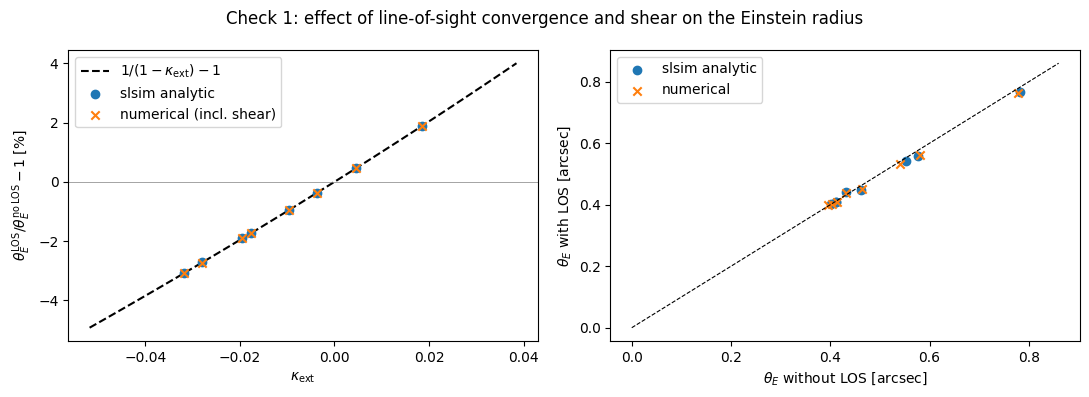

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

kappa_grid = np.linspace(los_table["kappa_ext"].min() - 0.02, los_table["kappa_ext"].max() + 0.02, 100)
axes[0].plot(kappa_grid, 100 * (1 / (1 - kappa_grid) - 1), "k--", label=r"$1/(1-\kappa_{\rm ext}) - 1$")
axes[0].scatter(los_table["kappa_ext"], los_table["dtheta_E/theta_E [%]"], label="slsim analytic", zorder=3)
axes[0].scatter(
    los_table["kappa_ext"], los_table["dtheta_E num/theta_E num [%]"], marker="x", label="numerical (incl. shear)", zorder=3
)
axes[0].axhline(0, color="gray", lw=0.5)
axes[0].set_xlabel(r"$\kappa_{\rm ext}$")
axes[0].set_ylabel(r"$\theta_E^{\rm LOS} / \theta_E^{\rm no\,LOS} - 1$ [%]")
axes[0].legend()

axes[1].scatter(los_table["theta_E (no LOS)"], los_table["theta_E (LOS)"], label="slsim analytic")
axes[1].scatter(los_table["theta_E num (no LOS)"], los_table["theta_E num (LOS)"], marker="x", label="numerical")
lim = [0, 1.1 * los_table[["theta_E (LOS)", "theta_E (no LOS)"]].max().max()]
axes[1].plot(lim, lim, "k--", lw=0.8)
axes[1].set_xlabel(r"$\theta_E$ without LOS [arcsec]")
axes[1].set_ylabel(r"$\theta_E$ with LOS [arcsec]")
axes[1].legend()

fig.suptitle("Check 1: effect of line-of-sight convergence and shear on the Einstein radius")
fig.tight_layout()
plt.show()

## 4. Check 2: Einstein radius with and without an assigned power-law slope

Without an assigned slope, `GalaxyDeflectors` builds every deflector with `gamma_pl = 2` (SIS/SIE).
Passing `gamma_pl=...` to `GalaxyDeflectors` assigns a slope, but the `EPL` mass model keeps
`sis_convention=True` by default: the Einstein radius is still normalised from $\sigma_v$ with the SIS
formula, so $\gamma_{\rm pl}$ only changes the shape of the profile, not $\theta_E$.
With `sis_convention=False`, $\theta_E$ is instead derived from the aperture-averaged velocity
dispersion of the power-law profile (`theta_E_from_vel_disp_epl`) and does depend on $\gamma_{\rm pl}$.

Both conventions are shown. The line of sight is switched off here to isolate the slope effect
(with LOS on, $\gamma_{\rm pl}$ additionally enters through the exponent $1/(\gamma_{\rm pl}-1)$ of the $\kappa_{\rm ext}$ correction).

In [8]:
gamma_pl_draw = {"mean": 2.0, "std_dev": 0.2}  # same form as GalaxyDeflectors(gamma_pl=...)
gamma_pl_grid = np.linspace(1.7, 2.3, 13)


def einstein_radius_with_slope(lens, gamma_pl, sis_convention):
    lens_slope = rebuild_lens(lens, los_class=NO_LOS, gamma_pl=gamma_pl, sis_convention=sis_convention)
    return lens_slope.einstein_radius[0], numerical_einstein_radius(lens_slope)


rows = []
for lens in lenses:
    gamma_pl = np.random.normal(gamma_pl_draw["mean"], gamma_pl_draw["std_dev"])
    theta_e_iso, theta_e_num_iso = einstein_radius_with_slope(lens, gamma_pl=2.0, sis_convention=True)
    theta_e_sis, theta_e_num_sis = einstein_radius_with_slope(lens, gamma_pl, sis_convention=True)
    theta_e_epl, theta_e_num_epl = einstein_radius_with_slope(lens, gamma_pl, sis_convention=False)
    rows.append(
        {
            "z_l": lens.deflector_redshift,
            "sigma_v [km/s]": lens.deflector_velocity_dispersion(),
            "gamma_pl": gamma_pl,
            "theta_E (gamma_pl=2)": theta_e_iso,
            "theta_E (sis_convention=True)": theta_e_sis,
            "dtheta_E/theta_E [%] (sis_convention=True)": 100 * (theta_e_sis / theta_e_iso - 1),
            "theta_E (sis_convention=False)": theta_e_epl,
            "dtheta_E/theta_E [%] (sis_convention=False)": 100 * (theta_e_epl / theta_e_iso - 1),
            "theta_E num (gamma_pl=2)": theta_e_num_iso,
            "theta_E num (sis_convention=False)": theta_e_num_epl,
        }
    )
slope_table = pd.DataFrame(rows)
slope_table

,z_l,sigma_v [km/s],gamma_pl,theta_E (gamma_pl=2),theta_E (sis_convention=True),dtheta_E/theta_E [%] (sis_convention=True),theta_E (sis_convention=False),dtheta_E/theta_E [%] (sis_convention=False),theta_E num (gamma_pl=2),theta_E num (sis_convention=False)
0,0.5723,146.7049,2.2736,0.4016,0.4016,0.0,0.4205,4.6992,0.3959,0.4133
1,0.4710,141.6127,1.6650,0.4123,0.4123,0.0,1.3785,234.3318,0.4132,1.3827
2,0.6101,158.1689,2.1842,0.4109,0.4109,0.0,0.4314,4.9779,0.4040,0.4235
3,0.5117,194.9755,1.6796,0.4324,0.4324,0.0,0.8836,104.3565,0.4314,0.8825
4,0.7050,171.2812,1.8318,0.4616,0.4616,0.0,0.8629,86.9444,0.4648,0.8692
5,0.3141,165.5048,1.8721,0.5525,0.5525,0.0,0.8538,54.5329,0.5404,0.8345
6,0.9172,219.0140,2.1253,0.5762,0.5762,0.0,0.6050,5.0135,0.5804,0.6092
7,0.2774,183.7316,1.9835,0.7819,0.7819,0.0,1.0168,30.0475,0.7790,1.0132


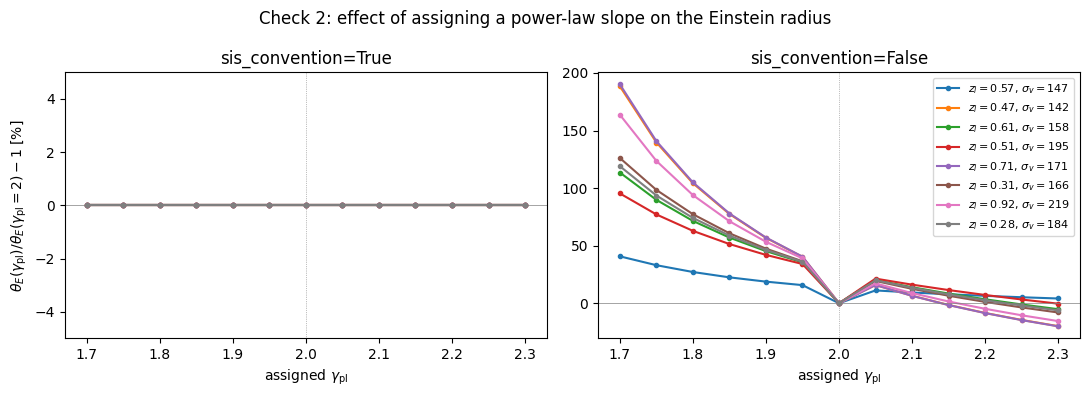

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

for ax, sis_convention in zip(axes, [True, False]):
    for lens in lenses:
        theta_e_iso, _ = einstein_radius_with_slope(lens, gamma_pl=2.0, sis_convention=sis_convention)
        theta_e_grid = [
            einstein_radius_with_slope(lens, gamma_pl, sis_convention)[0] for gamma_pl in gamma_pl_grid
        ]
        ax.plot(
            gamma_pl_grid,
            100 * (np.array(theta_e_grid) / theta_e_iso - 1),
            marker=".",
            label=rf"$z_l={lens.deflector_redshift:.2f}$, $\sigma_v={lens.deflector_velocity_dispersion():.0f}$",
        )
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(2, color="gray", lw=0.5, ls=":")
    ax.set_xlabel(r"assigned $\gamma_{\rm pl}$")
    ax.set_title(f"sis_convention={sis_convention}")

axes[0].set_ylabel(r"$\theta_E(\gamma_{\rm pl}) / \theta_E(\gamma_{\rm pl}=2) - 1$ [%]")
axes[0].set_ylim(-5, 5)
axes[1].legend(fontsize=8)
fig.suptitle("Check 2: effect of assigning a power-law slope on the Einstein radius")
fig.tight_layout()
plt.show()

The `sis_convention=False` curves are discontinuous at $\gamma_{\rm pl}=2$: `theta_E_from_vel_disp_epl` special-cases
`gamma == 2` to the SIS formula, while for $\gamma_{\rm pl}\neq2$ it normalises $\theta_E$ to the aperture-averaged
velocity dispersion of the power law within the half-light radius. The two normalisations do not agree in the
$\gamma_{\rm pl}\to2$ limit, so part of the "slope effect" seen above is this convention jump. The cell below isolates it.

In [10]:
rows = []
for lens in lenses:
    theta_e_iso, _ = einstein_radius_with_slope(lens, gamma_pl=2.0, sis_convention=False)
    theta_e_shallow, _ = einstein_radius_with_slope(lens, gamma_pl=2.0 - 1e-3, sis_convention=False)
    theta_e_steep, _ = einstein_radius_with_slope(lens, gamma_pl=2.0 + 1e-3, sis_convention=False)
    rows.append(
        {
            "z_l": lens.deflector_redshift,
            "sigma_v [km/s]": lens.deflector_velocity_dispersion(),
            "theta_E (gamma_pl=2)": theta_e_iso,
            "jump at gamma_pl -> 2- [%]": 100 * (theta_e_shallow / theta_e_iso - 1),
            "jump at gamma_pl -> 2+ [%]": 100 * (theta_e_steep / theta_e_iso - 1),
        }
    )
pd.DataFrame(rows)

,z_l,sigma_v [km/s],theta_E (gamma_pl=2),jump at gamma_pl -> 2- [%],jump at gamma_pl -> 2+ [%]
0,0.5723,146.7049,0.4016,13.2905,13.1990
1,0.4710,141.6127,0.4123,27.1738,26.6887
2,0.6101,158.1689,0.4109,27.4085,27.1031
3,0.5117,194.9755,0.4324,27.4281,27.1758
4,0.7050,171.2812,0.4616,27.2242,26.7358
5,0.3141,165.5048,0.5525,27.4033,27.0639
6,0.9172,219.0140,0.5762,27.3661,26.9351
7,0.2774,183.7316,0.7819,27.5010,27.1812


## Summary

- **LOS**: the analytic Einstein radius follows $\theta_E \propto 1/(1-\kappa_{\rm ext})$ exactly, i.e. a
  fractional change of $\simeq\kappa_{\rm ext}$ (a few per cent for typical draws). External shear changes the
  numerically measured effective Einstein radius only at the sub-per-cent level on top of that.
- **Slope, default convention** (`sis_convention=True`, what `GalaxyDeflectors(gamma_pl=...)` gives you):
  assigning $\gamma_{\rm pl}$ leaves the Einstein radius unchanged — the profile shape changes, the normalisation does not.
- **Slope, `sis_convention=False`**: $\theta_E$ depends strongly on $\gamma_{\rm pl}$ (tens of per cent for
  $\gamma_{\rm pl}<2$, milder for $\gamma_{\rm pl}>2$), but a sizeable part of that is a discontinuity at
  $\gamma_{\rm pl}=2$ between the SIS normalisation and the aperture-velocity-dispersion normalisation in
  `theta_E_from_vel_disp_epl`. If this convention is used, comparisons against the $\gamma_{\rm pl}=2$ case
  should account for that jump.